In [ ]:
!pip install -q datasets huggingface_hub pandas numpy matplotlib seaborn plotly

In [ ]:
from huggingface_hub import login
login()

from datasets import load_dataset

ds = load_dataset(
    "ai4bharat/IndicVoices",
    "hindi",
    split="valid",
    streaming=True
)

print(ds)

======== Test =========

In [ ]:
from datasets import load_dataset
import pandas as pd

languages = [
    "assamese",
    "bengali",
    "bodo",
    "dogri",
    "gujarati",
    "hindi",
    "kannada",
    "kashmiri",
    "konkani",
    "maithili",
    "malayalam",
    "manipuri",
    "marathi",
    "nepali",
    "odia",
    "punjabi",
    "sanskrit",
    "santali",
    "sindhi",
    "tamil",
    "telugu",
    "urdu"
]

all_data = []

for language in languages:

    print("Loading:", language)

    ds = load_dataset(
        "ai4bharat/IndicVoices",
        language,
        split="train",
        streaming=True
    )

    samples = list(ds.take(500))

    temp_df = pd.DataFrame(samples)

    all_data.append(temp_df)

df_all = pd.concat(all_data, ignore_index=True)

print("Total records:", len(df_all))

Loading: assamese


README.md:   0%|          | 0.00/32.2k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/112 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/112 [00:00<?, ?it/s]

Loading: bengali


Resolving data files:   0%|          | 0/112 [00:00<?, ?it/s]

... (59 outputs left out)

Loading: urdu


Resolving data files:   0%|          | 0/112 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Total records: 11000


======== Test =========

In [ ]:
df_all.describe()

,duration,samples
count,11000.000000,11000.000000
mean,6.774721,108395.537727
std,5.256211,84099.381310
min,0.204000,3264.000000
25%,2.176000,34816.000000
50%,5.924500,94792.000000
75%,9.977500,159640.000000
max,29.834000,477344.000000


In [ ]:
df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   audio_filepath          11000 non-null  object 
 1   text                    11000 non-null  object 
 2   duration                11000 non-null  float64
 3   lang                    11000 non-null  object 
 4   samples                 11000 non-null  int64  
 5   verbatim                11000 non-null  object 
 6   normalized              11000 non-null  object 
 7   speaker_id              11000 non-null  object 
 8   scenario                11000 non-null  object 
 9   task_name               11000 non-null  object 
 10  gender                  11000 non-null  object 
 11  age_group               11000 non-null  object 
 12  job_type                11000 non-null  object 
 13  qualification           11000 non-null  object 
 14  area                    11000 non-null

In [ ]:
df_all.shape

(11000, 21)

In [ ]:
df_all.isnull().sum()

,0
audio_filepath,0
text,0
duration,0
lang,0
samples,0
verbatim,0
normalized,0
speaker_id,0
scenario,0
task_name,0


In [ ]:
for col in df_all.columns:
  if df_all[col].dtype=='object':
    print()
    print(col)
    print(df_all[col].unique())


audio_filepath
 <datasets.features._torchcodec.AudioDecoder object at 0x7b1bf660aad0> ...

text
["মই মোৰ বস্তুৰ তালিকাৰ পৰা প্র' নেচাৰ আটা আঁতৰাব বিচাৰোঁ"
 'নলবাৰী বাক্সা যোৰহাট শিৱসাগৰ আৰু কোকোৰাঝাৰ' "হেল্ল'" ...
 'ہاں ایک کلو پونڈ' 'ہاں اور لابسٹر چاہیے آدھا کلو'
 'ہاں اور کریب کریبس چاہیے آدھا کلو کریبس آدھا کلو']

lang
['as' 'bn' 'brx' 'doi' 'gu' 'hi' 'kn' 'ks' 'kok' 'mai' 'ml' 'mni' 'mr'
 'ne' 'or' 'pa' 'sa' 'sat' 'sd' 'ta' 'te' 'ur']

verbatim
["মই মোৰ বস্তুৰ তালিকাৰ পৰা প্র' নেচাৰ আটা আঁতৰাব বিচাৰোঁ"
 'নলবাৰী বাক্সা যোৰহাট শিৱসাগৰ আৰু কোকোৰাঝাৰ' "হেল্ল'" ...
 'ہاں ایک کلو پونڈ' 'ہاں اور لابسٹر چاہیے آدھا کلو'
 'ہاں اور کریب کریبس چاہیے آدھا کلو کریبس آدھا کلو']

normalized
["মই মোৰ বস্তুৰ তালিকাৰ পৰা প্র' নেচাৰ আটা আঁতৰাব বিচাৰোঁ"
 'নলবাৰী বাক্সা যোৰহাট শিৱসাগৰ আৰু কোকোৰাঝাৰ' "হেল্ল'" ...
 'ہاں ایک کلو پونڈ' 'ہاں اور لابسٹر چاہیے آدھا کلو'
 'ہاں اور کریب کریبس چاہیے آدھا کلو کریبس آدھا کلو']

speaker_id
['S4259524500389946' 'S4259530100397673' 'S4258323200368213' ...
 'S4258485

In [ ]:
for col in df_all.select_dtypes(include='object').columns:
    print(f"\n--- {col} ---")
    print(df_all[col].value_counts(dropna=False))


--- audio_filepath ---
audio_filepath
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf8c8eeb0>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1c4820d940>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1c2232fc50>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf660aad0>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf66108a0>    1
                                                                        ..
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf63e5c50>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf641e030>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf641db80>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf63f0c50>    1
<datasets.features._torchcodec.AudioDecoder object at 0x7b1bf63f0a50>    1
Name: count, Length: 11000, dtype: int64

--- text ---
text
<unintelligible>                                                            

In [ ]:
import plotly.express as px
import pandas as pd

In [ ]:
language_counts = df_all["lang"].value_counts().reset_index()
language_counts.columns = ["lang", "count"]

fig = px.bar(
    language_counts,
    x="lang",
    y="count",
    title="Number of Speech Samples per Language",
    labels={
        "lang": "Language",
        "count": "Number of Samples"
    }
)

fig.update_layout(
    xaxis_tickangle=-45,
    template="plotly_dark"
)

fig.show()

In [ ]:
scenario_counts = df_all["scenario"].value_counts().reset_index()
scenario_counts.columns = ["scenario", "count"]

fig = px.pie(
    scenario_counts,
    names="scenario",
    values="count",
    title="Speech Scenario Distribution"
)

fig.update_layout(
    template="plotly_dark"
)

fig.show()

In [ ]:
import plotly.express as px

df_plot = df_all.copy()

df_plot["speaker_num"] = df_plot["speaker_id"].astype("category").cat.codes

fig = px.scatter(
    df_plot,
    x="speaker_num",
    y="duration",
    color="lang",
    hover_data=[
        "speaker_id",
        "scenario",
        "gender",
        "age_group",
        "state"
    ],
    title="Speech Duration Across Speakers",
    opacity=0.5,
    size="duration"
)

fig.update_layout(
    template="plotly_dark",
    xaxis_title="Speaker",
    yaxis_title="Duration (seconds)"
)

fig.show()

In [ ]:
import plotly.express as px

fig = px.box(
    df_all,
    x="lang",
    y="duration",
    title="Speech Duration Distribution by Language",
    color='lang',
    labels={
        "lang": "Language",
        "duration": "Duration (seconds)"
    }
)

fig.update_layout(
    template="plotly_dark",
    xaxis_tickangle=-45
)

fig.show()

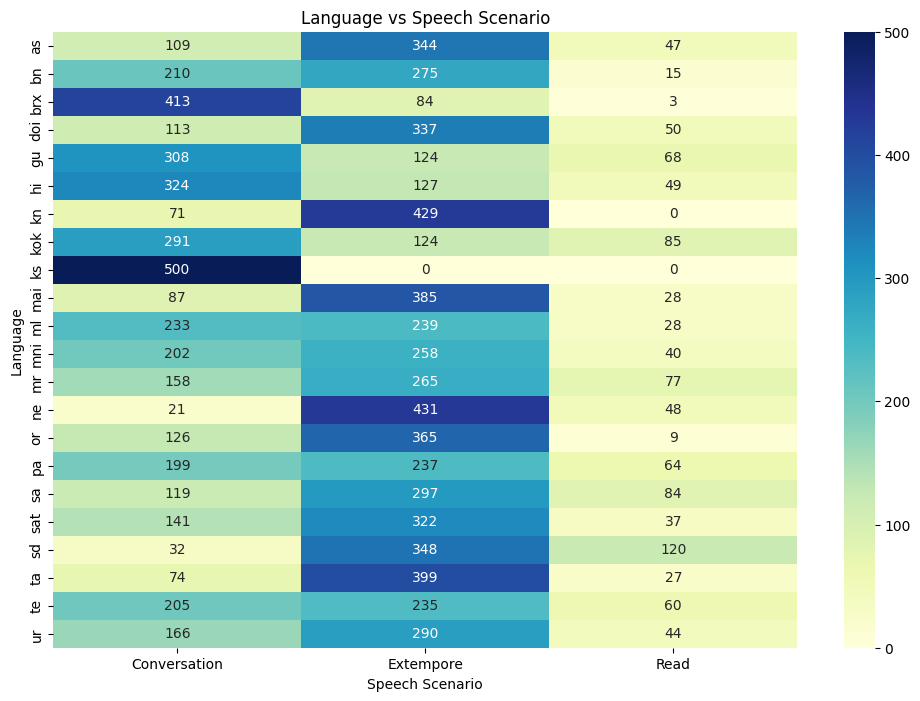

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

heatmap_data = pd.crosstab(
    df_all["lang"],
    df_all["scenario"]
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    #cmap="Set2"
)

plt.title("Language vs Speech Scenario")
plt.xlabel("Speech Scenario")
plt.ylabel("Language")

plt.show()

In [ ]:
import plotly.express as px

fig = px.box(
    df_all,
    x="gender",
    y="duration",
    color="gender",
    title="Speech Duration Distribution by Gender",
    labels={
        "gender": "Gender",
        "duration": "Speech Duration (seconds)"
    },
    template="plotly_dark"
)

fig.show()